# Model experiments
Reads the run log and artifacts written by `python -m src.pipeline --stages train`.

In [1]:
import sys, warnings, json
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.utils import load_config, load
from src.features.build import build_features, build_labels, data_end, feature_columns
cfg = load_config(); FIG = '../docs/figures/'
import os; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style='whitegrid', palette=['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
tx = pd.read_parquet(cfg['paths']['interim'])
import shap
from src.explainability.explain import ChurnExplainer, label
card = load('model_card.json')

In [2]:
runs = pd.DataFrame([json.loads(l) for l in open(cfg['paths']['artifacts'] + '/runs.jsonl')])
runs[runs.task == 'churn'][['model', 'cv_roc_auc', 'val_roc_auc', 'roc_auc', 'recall', 'precision', 'f1', 'accuracy', 'train_seconds']].round(3)

,model,cv_roc_auc,val_roc_auc,roc_auc,recall,precision,f1,accuracy,train_seconds
0,logistic_regression,0.803,0.806,0.804,0.895,0.705,0.789,0.729,23.58
1,decision_tree,0.782,0.796,0.782,0.843,0.723,0.778,0.729,1.58
2,random_forest,0.810,0.813,0.811,0.874,0.718,0.789,0.735,81.03
3,xgboost,0.807,0.813,0.805,0.888,0.707,0.787,0.729,26.00
4,lightgbm,0.803,0.813,0.805,0.857,0.721,0.783,0.731,23.19
5,knn,0.804,0.805,0.800,0.955,0.668,0.786,0.706,1.85
6,ann,NaN,0.819,0.796,0.913,0.685,0.783,0.714,4.06
7,lstm,NaN,0.804,0.809,0.919,0.728,0.813,0.760,6.05


,roc_auc,recall,precision,f1,accuracy
model,,,,,
random_forest,0.811,0.874,0.718,0.789,0.735
lstm,0.809,0.919,0.728,0.813,0.760
lightgbm,0.805,0.857,0.721,0.783,0.731
xgboost,0.805,0.888,0.707,0.787,0.729
logistic_regression,0.804,0.895,0.705,0.789,0.729
knn,0.800,0.955,0.668,0.786,0.706
ann,0.796,0.913,0.685,0.783,0.714
decision_tree,0.782,0.843,0.723,0.778,0.729


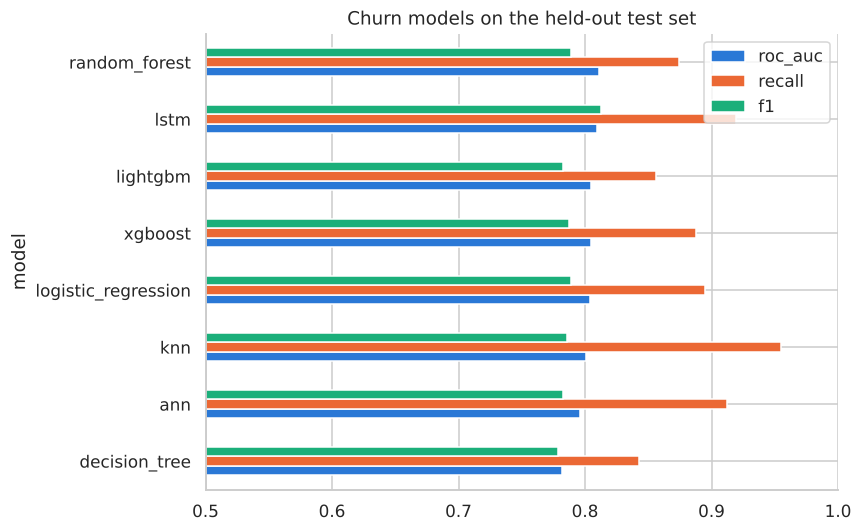

In [3]:
cmp = pd.DataFrame(card['comparison']).set_index('model')[['roc_auc', 'recall', 'precision', 'f1', 'accuracy']]
ax = cmp[['roc_auc', 'recall', 'f1']].sort_values('roc_auc').plot.barh(figsize=(8, 5)); ax.set_xlim(0.5, 1)
ax.set_title('Churn models on the held-out test set'); plt.tight_layout(); plt.savefig(FIG + 'model_comparison.png'); cmp.round(3)

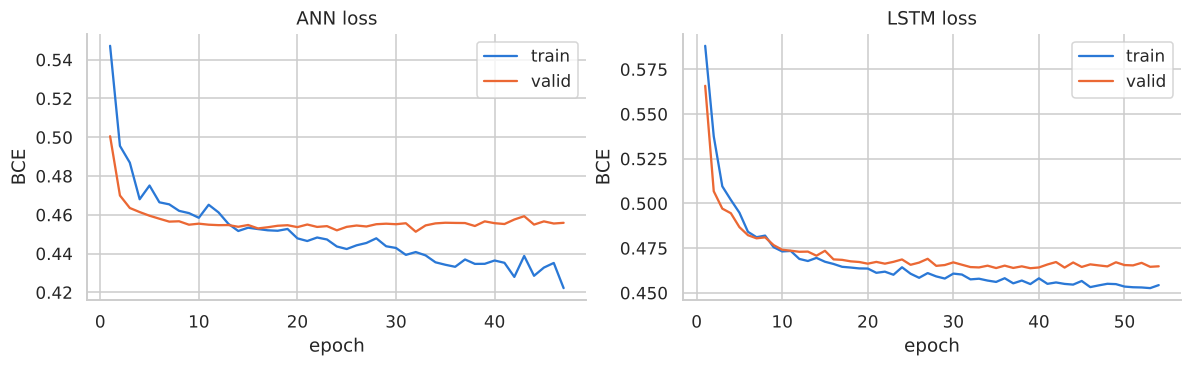

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, name in zip(ax, ['ann', 'lstm']):
    lc = pd.DataFrame(card['loss_curves'][name]).set_index('epoch'); lc.plot(ax=a); a.set_title(f'{name.upper()} loss'); a.set_ylabel('BCE')
plt.tight_layout(); plt.savefig(FIG + 'loss_curves.png')

In [5]:
pd.Series(card['error_correlation']).sort_values().round(2).to_frame('error correlation')

,error correlation
decision_tree|knn,0.60
knn|lightgbm,0.65
knn|random_forest,0.69
ann|decision_tree,0.70
decision_tree|lstm,0.70
knn|lstm,0.71
ann|lstm,0.73
ann|lightgbm,0.73
lightgbm|lstm,0.73
knn|xgboost,0.73


## SHAP

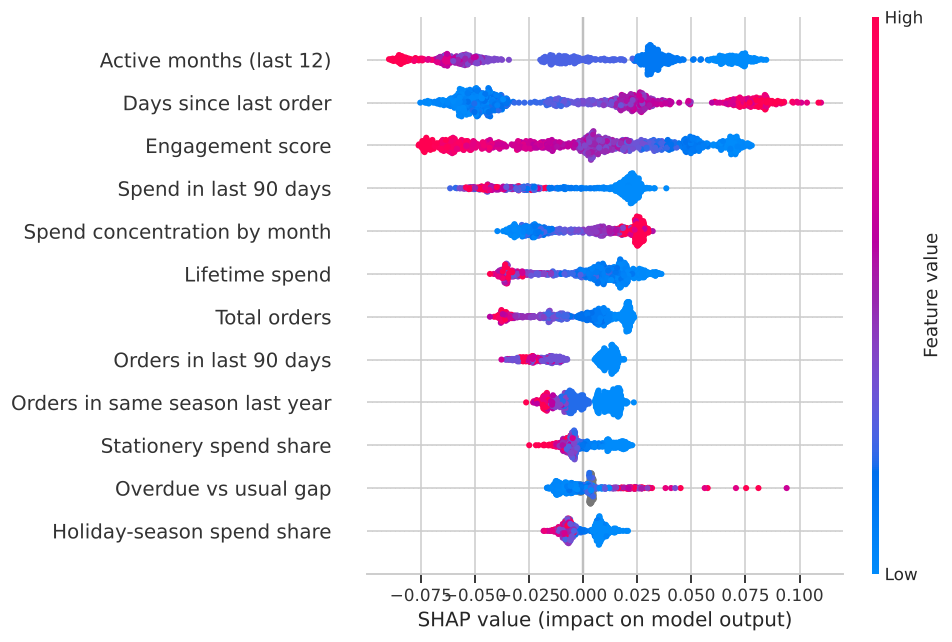

In [6]:
snap = pd.read_parquet(f"{cfg['paths']['processed']}/churn_snapshot.parquet")
cols = card['features']
model = load('churn_model.joblib'); exp = ChurnExplainer(model, load('background.joblib'), cfg['seed'])
X = snap[cols].sample(800, random_state=0); sv = exp.shap_values(X)
shap.summary_plot(sv, X.rename(columns=label), show=False, max_display=12, plot_size=(9, 6)); plt.tight_layout(); plt.savefig(FIG + 'shap_summary.png')

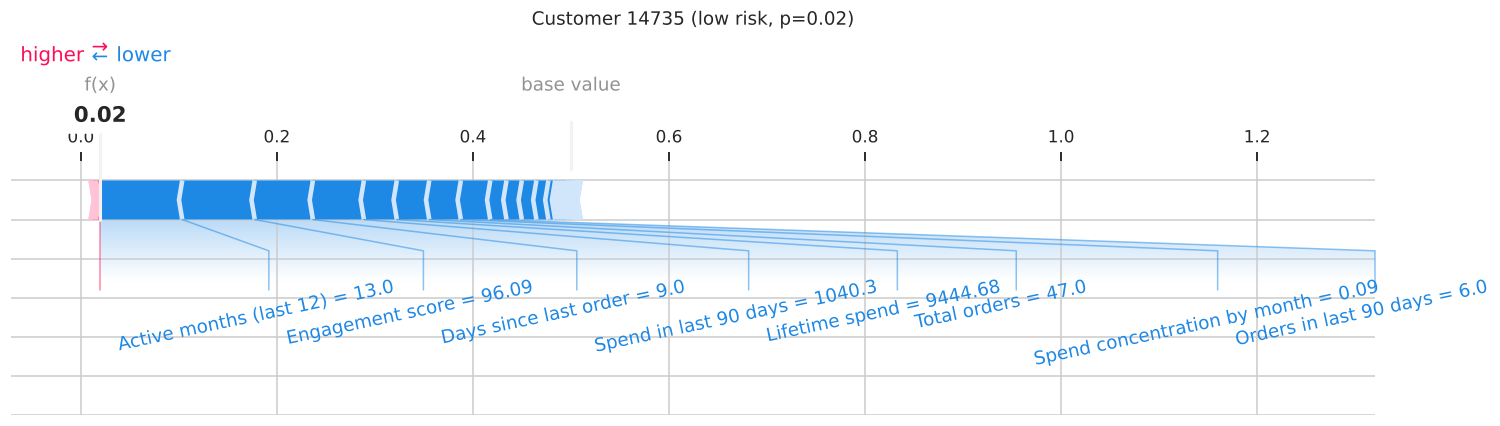

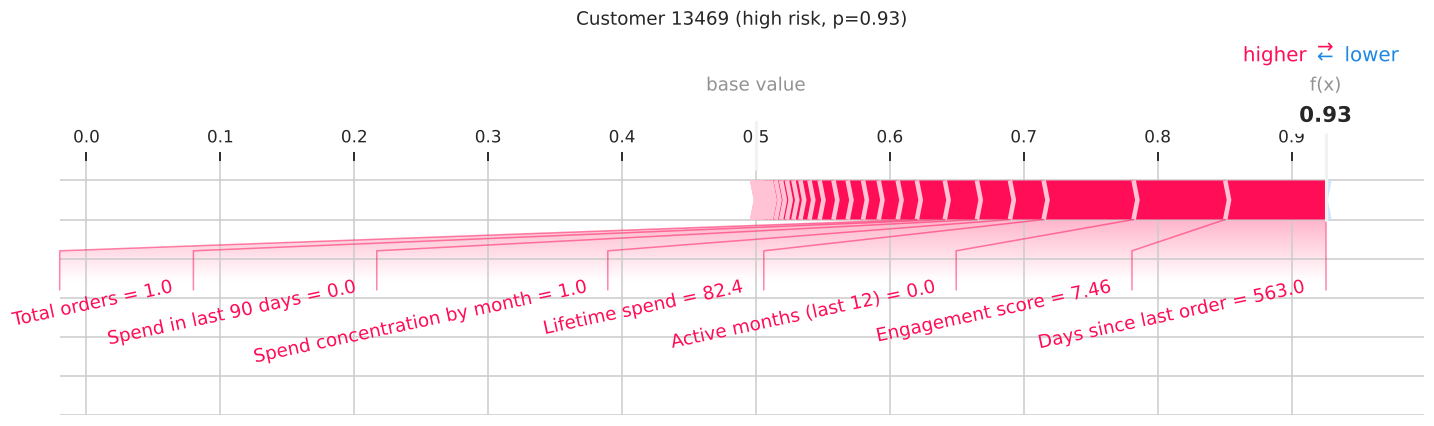

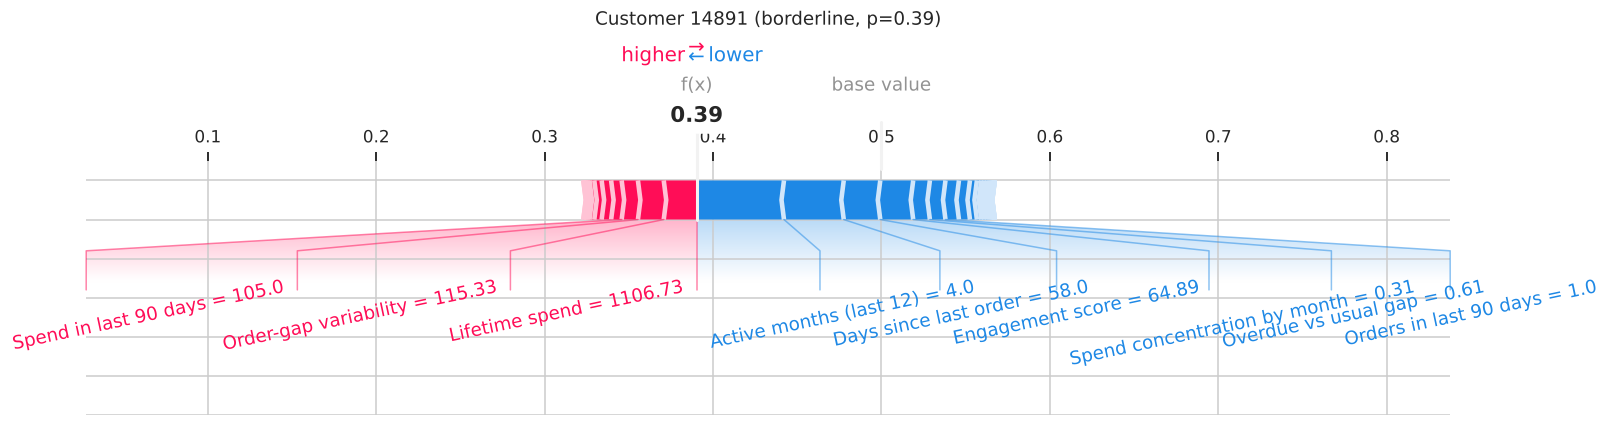

In [7]:
p = model.predict_proba(X)[:, 1]
picks = {'low risk': X.index[np.argmin(p)], 'high risk': X.index[np.argmax(p)], 'borderline': X.index[np.argmin(abs(p - card['threshold']))]}
for name, cid in picks.items():
    i = X.index.get_loc(cid)
    shap.force_plot(exp.base_value, sv[i], X.iloc[i].round(2).rename(index=label), matplotlib=True, show=False, figsize=(16, 3), text_rotation=12)
    plt.title(f'Customer {cid} ({name}, p={p[i]:.2f})', y=1.5); plt.savefig(FIG + f"force_{name.replace(' ', '_')}.png", bbox_inches='tight'); plt.show()

## LIME vs SHAP for the borderline customer

In [8]:
row = snap.loc[picks['borderline']]
lime_w = pd.DataFrame(exp.lime_weights(row, 3000)).set_index('feature')['weight']
shap_w = pd.Series(sv[X.index.get_loc(picks['borderline'])], index=cols)
both = pd.DataFrame({'LIME': lime_w, 'SHAP': shap_w.reindex(lime_w.index)}).rename(index=label)
ax = both.plot.barh(figsize=(8, 4.5)); ax.set_title('LIME vs SHAP for the borderline customer')
plt.tight_layout(); plt.savefig(FIG + 'lime_vs_shap.png'); both.round(3)

,LIME,SHAP
feature,,
Active months (last 12),-0.069,-0.052
Days since last order,-0.041,-0.035
Based in EIRE,0.041,0.000
Overdue vs usual gap,-0.022,-0.010
Orders in same season last year,-0.021,-0.008
Orders in last 90 days,-0.021,-0.009
Engagement score,-0.017,-0.022
Avg. days between orders,0.016,0.006


## Partial dependence

In [9]:
fig, ax = plt.subplots(1, len(card['pdp']), figsize=(13, 3.4))
for a, (f, pts) in zip(ax, card['pdp'].items()):
    d = pd.DataFrame(pts); a.plot(d.x, d.y, color='#1baf7a'); a.set_title(label(f)); a.set_ylabel('P(churn)')
plt.tight_layout(); plt.savefig(FIG + 'pdp.png')

## Segmentation diagnostics

In [10]:
seg = load('segmentation_report.json'); el = pd.DataFrame(seg['elbow']).set_index('k')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2)); el.inertia.plot(ax=ax[0], marker='o', title='Elbow (inertia)')
el.silhouette.plot(ax=ax[1], marker='o', title='Silhouette'); plt.tight_layout(); plt.savefig(FIG + 'segmentation_k.png')
{k: seg[k] for k in ['k', 'kmeans']} | {'gmm': {k: v for k, v in seg['gmm'].items() if k != 'bic'}}

{'k': 6,
 'kmeans': {'silhouette': 0.2605783655429145,
  'davies_bouldin': 1.2127733774322274},
 'gmm': {'k': 7,
  'silhouette': 0.12881939341122206,
  'davies_bouldin': 3.0511676722652195,
  'ari_vs_kmeans': 0.34383199872306847}}

## CLV

In [11]:
pd.DataFrame(card['clv']['validation']).T.round(3).assign(selected=lambda d: d.index == card['clv']['model'])

,mae,rmse,r2,r2_log,cv_r2,selected
ridge,1105.035,3879.485,0.880,-0.185,0.522,False
lightgbm_tweedie,1042.280,6991.319,0.610,0.115,0.559,True
lightgbm_log,1135.801,9281.807,0.313,0.322,0.297,False
